# Análise Comparativa — GraphRAG Baseline vs Prompt-Tuned
**Domínio:** Hepatologia clínica  
**Objetivo:** Comparar extração de entidades clínicas entre os dois sistemas e calcular Precision@K e Recall@K

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Paleta de cores consistente
COR_BASE   = '#4C72B0'   # azul  — baseline
COR_TUNED  = '#DD8452'   # laranja — prompt-tuned
COR_DELTA  = '#55A868'   # verde — diferença

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'font.family': 'DejaVu Sans',
})

print('Bibliotecas carregadas.')

Bibliotecas carregadas.


In [15]:
import os
print("CWD:", os.getcwd())

CWD: c:\Users\Matheus\Documents\trabalho de conclusão de curso\anamnese\scripts


## 1. Carga dos dados

In [2]:
# ── AJUSTE OS CAMINHOS ──────────────────────────────────────────
PATH_BASE  = r"../results/dataset/abril-2026/dataset_no-prompt-tuning_20260423_214117.csv"
PATH_TUNED = r"../results/dataset/abril-2026/dataset_prompt-tuning_20260423_202917.csv"
# ────────────────────────────────────────────────────────────────

df_base  = pd.read_csv(PATH_BASE,  dtype=str).fillna('')
df_tuned = pd.read_csv(PATH_TUNED, dtype=str).fillna('')

print(f'Baseline   — linhas: {len(df_base):>6} | prontuários: {df_base["prontuario_id"].nunique():>4}')
print(f'Prompt-tuned — linhas: {len(df_tuned):>6} | prontuários: {df_tuned["prontuario_id"].nunique():>4}')
df_base.head(2)

Baseline   — linhas:  69589 | prontuários: 2367
Prompt-tuned — linhas:   6748 | prontuários:  445


,prontuario_id,condicao,tipo_entidade,texto_evidencia,chunk_id,entity_id,community_id,community_title,community_summary
0,10000024,AMBULATORIO DE HEPATOLOGIA,ORGANIZATION,"prontuario,Anamnese/Evolução,descricao,categor...",1e24af2f0cdecfcf4a7ade8dadc6c07eaf1a4d09d72851...,c5f45df4-718f-41ff-a6d2-e20073d46bb9,4883.0,AMBULATORIO DE HEPATOLOGIA and Hepatology Care...,The community centers on the AMBULATORIO DE HE...
1,10000024,BANHO DE RIO,EVENT,"prontuario,Anamnese/Evolução,descricao,categor...",1e24af2f0cdecfcf4a7ade8dadc6c07eaf1a4d09d72851...,ff5da214-e651-4be7-9024-ef0652249bec,6103.0,BANHO DE RIO and Schistosomiasis Exposure Netw...,"The community centers on BANHO DE RIO, a histo..."


## 2. Estatísticas gerais — Baseline vs Prompt-Tuned

In [20]:
def stats_gerais(df, nome):
    return {
        'Sistema': nome,
        'Total de linhas': len(df),
        'Prontuários únicos': df['prontuario_id'].nunique(),
        'Entidades únicas (condicao)': df['condicao'].nunique(),
        'Tipos de entidade únicos': df['tipo_entidade'].nunique(),
        'Comunidades únicas': df['community_id'].nunique(),
        'Entidades por prontuário (média)': round(df.groupby('prontuario_id')['entity_id'].nunique().mean(), 2),
        'Entidades por prontuário (mediana)': df.groupby('prontuario_id')['entity_id'].nunique().median(),
        'Comunidades por prontuário (média)': round(df.groupby('prontuario_id')['community_id'].nunique().mean(), 2),
    }

resumo = pd.DataFrame([stats_gerais(df_base, 'Baseline'), stats_gerais(df_tuned, 'Prompt-Tuned')])
resumo = resumo.set_index('Sistema').T
resumo['Delta (T - B)'] = pd.to_numeric(resumo['Prompt-Tuned'], errors='coerce') - pd.to_numeric(resumo['Baseline'], errors='coerce')
resumo['Delta (T - B)'] = resumo['Delta (T - B)'].apply(lambda x: f'+{x:.2f}' if x > 0 else f'{x:.2f}' if pd.notna(x) else '')
print(resumo.to_string())

Sistema                             Baseline  Prompt-Tuned Delta (T - B)
Total de linhas                     69589.00       6748.00     -62841.00
Prontuários únicos                   2367.00        445.00      -1922.00
Entidades únicas (condicao)         26811.00       2417.00     -24394.00
Tipos de entidade únicos                7.00         10.00         +3.00
Comunidades únicas                   4851.00       1278.00      -3573.00
Entidades por prontuário (média)       25.78         13.36        -12.42
Entidades por prontuário (mediana)     19.00         11.00         -8.00
Comunidades por prontuário (média)     16.66         12.07         -4.59


## 3. Visualizações — Estatísticas simples

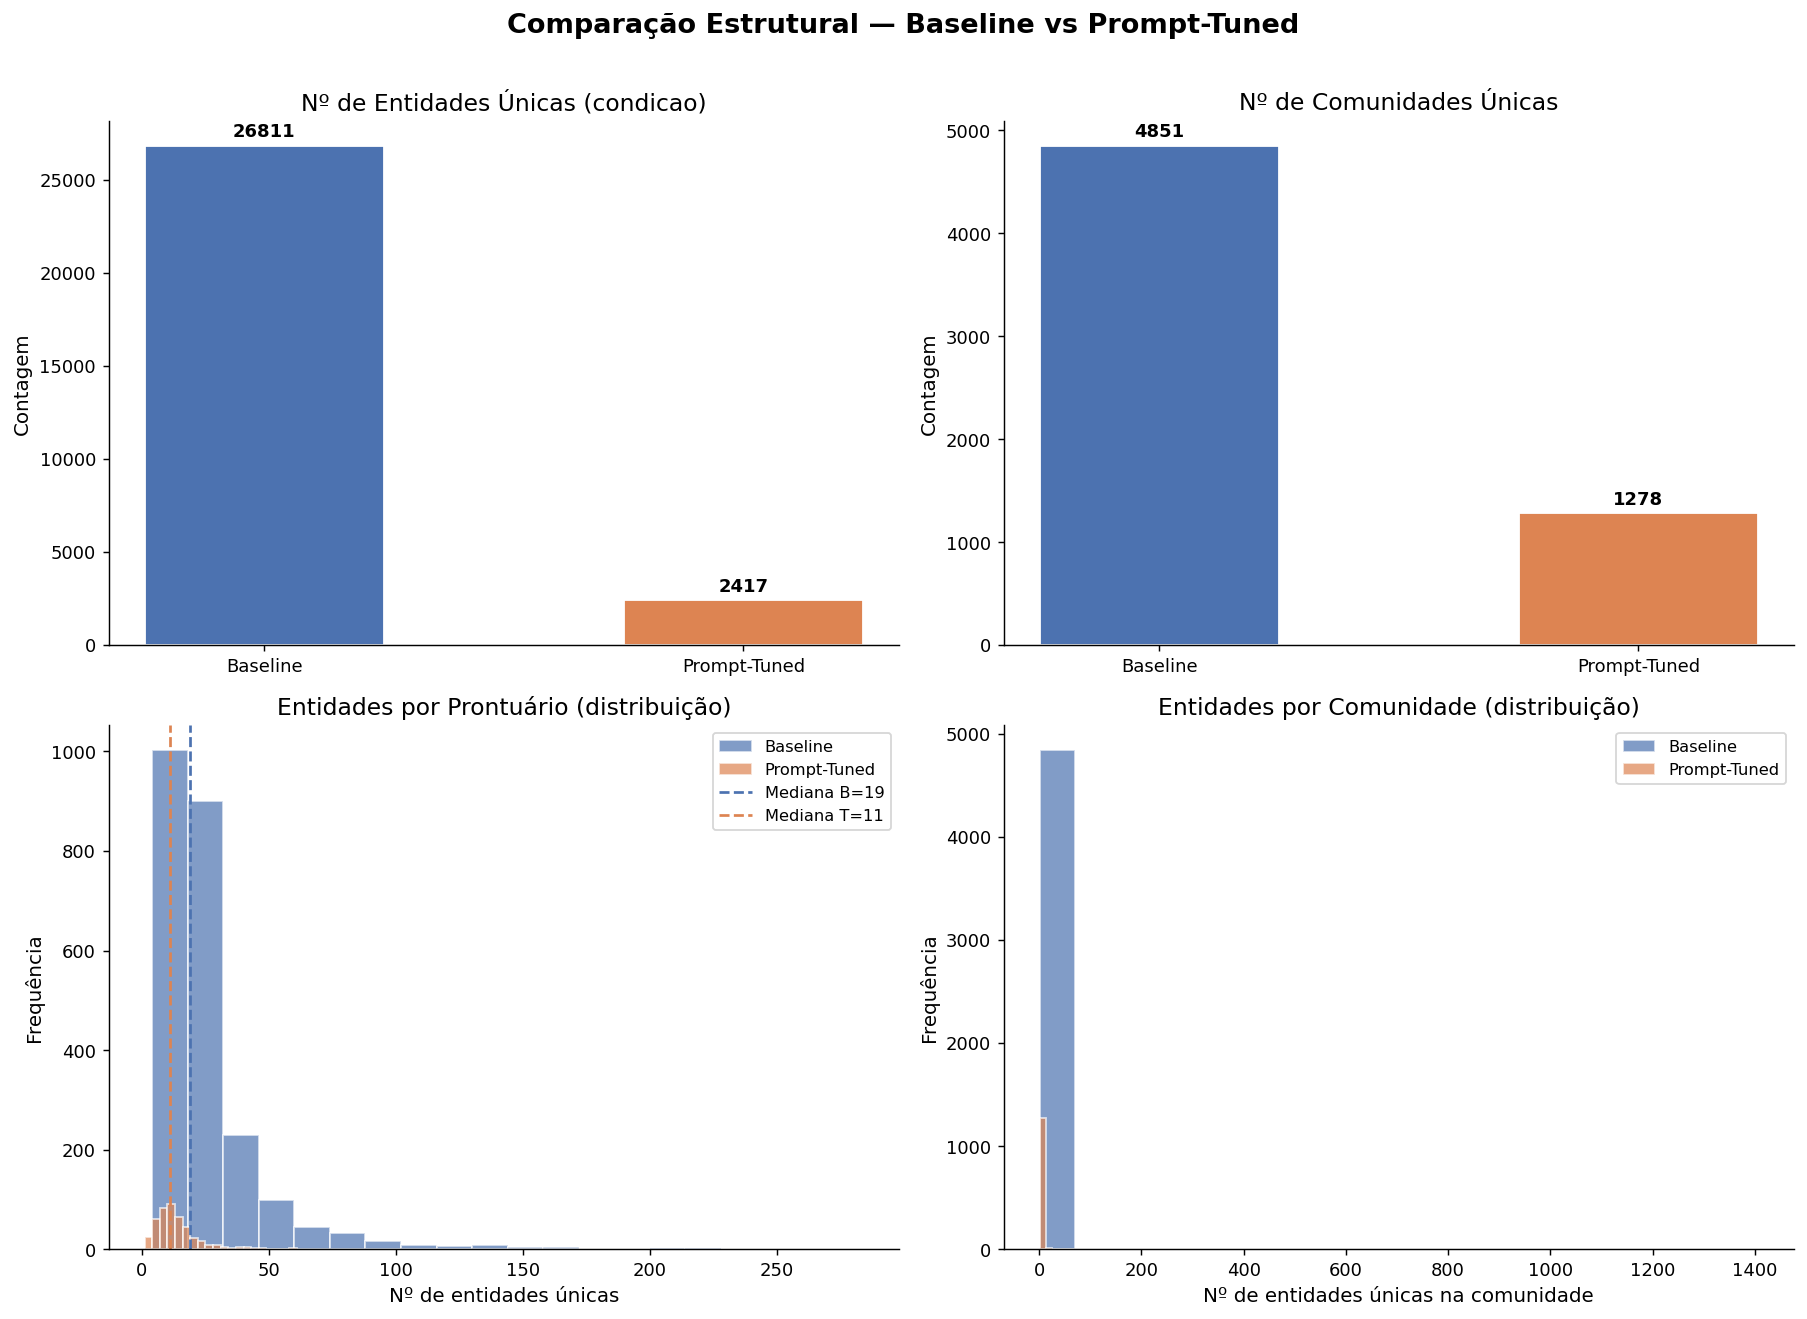

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Comparação Estrutural — Baseline vs Prompt-Tuned', fontsize=15, fontweight='bold', y=1.01)

sistemas  = ['Baseline', 'Prompt-Tuned']
cores     = [COR_BASE, COR_TUNED]

# ── 3.1 Nº de entidades únicas ───────────────────────────────
ax = axes[0, 0]
vals = [df_base['condicao'].nunique(), df_tuned['condicao'].nunique()]
bars = ax.bar(sistemas, vals, color=cores, width=0.5, edgecolor='white')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
            str(v), ha='center', va='bottom', fontweight='bold')
ax.set_title('Nº de Entidades Únicas (condicao)')
ax.set_ylabel('Contagem')

# ── 3.2 Nº de comunidades ────────────────────────────────────
ax = axes[0, 1]
vals = [df_base['community_id'].nunique(), df_tuned['community_id'].nunique()]
bars = ax.bar(sistemas, vals, color=cores, width=0.5, edgecolor='white')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
            str(v), ha='center', va='bottom', fontweight='bold')
ax.set_title('Nº de Comunidades Únicas')
ax.set_ylabel('Contagem')

# ── 3.3 Distribuição de entidades por prontuário ─────────────
ax = axes[1, 0]
ent_base  = df_base.groupby('prontuario_id')['entity_id'].nunique()
ent_tuned = df_tuned.groupby('prontuario_id')['entity_id'].nunique()
ax.hist(ent_base,  bins=20, alpha=0.7, color=COR_BASE,  label='Baseline',      edgecolor='white')
ax.hist(ent_tuned, bins=20, alpha=0.7, color=COR_TUNED, label='Prompt-Tuned', edgecolor='white')
ax.axvline(ent_base.median(),  color=COR_BASE,  linestyle='--', linewidth=1.5, label=f'Mediana B={ent_base.median():.0f}')
ax.axvline(ent_tuned.median(), color=COR_TUNED, linestyle='--', linewidth=1.5, label=f'Mediana T={ent_tuned.median():.0f}')
ax.set_title('Entidades por Prontuário (distribuição)')
ax.set_xlabel('Nº de entidades únicas')
ax.set_ylabel('Frequência')
ax.legend(fontsize=9)

# ── 3.4 Distribuição de entidades por comunidade ─────────────
ax = axes[1, 1]
com_base  = df_base.groupby('community_id')['entity_id'].nunique()
com_tuned = df_tuned.groupby('community_id')['entity_id'].nunique()
ax.hist(com_base,  bins=20, alpha=0.7, color=COR_BASE,  label='Baseline',      edgecolor='white')
ax.hist(com_tuned, bins=20, alpha=0.7, color=COR_TUNED, label='Prompt-Tuned', edgecolor='white')
ax.set_title('Entidades por Comunidade (distribuição)')
ax.set_xlabel('Nº de entidades únicas na comunidade')
ax.set_ylabel('Frequência')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig1_estatisticas_gerais.png', bbox_inches='tight')
plt.show()

## 4. Top entidades — Baseline vs Prompt-Tuned

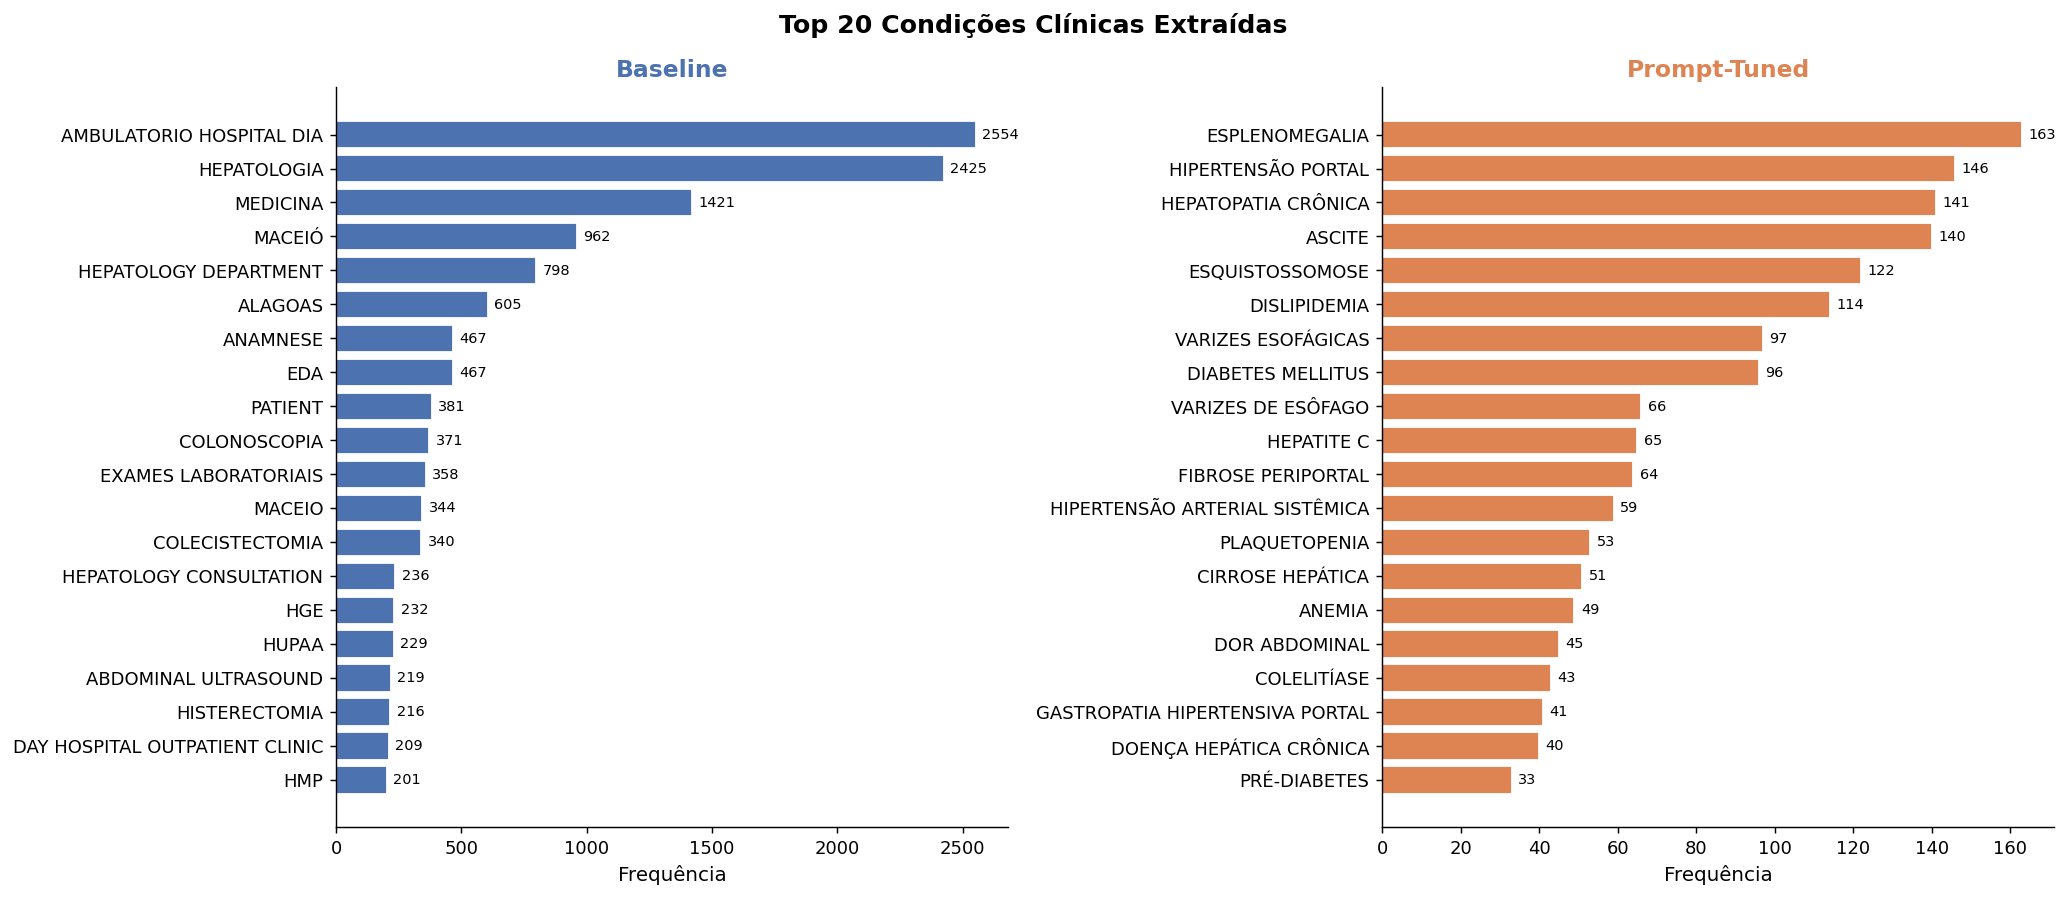

In [22]:
TOP_N = 20

top_base  = df_base['condicao'].value_counts().head(TOP_N)
top_tuned = df_tuned['condicao'].value_counts().head(TOP_N)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(f'Top {TOP_N} Condições Clínicas Extraídas', fontsize=14, fontweight='bold')

for ax, top, cor, titulo in zip(
    axes,
    [top_base, top_tuned],
    [COR_BASE, COR_TUNED],
    ['Baseline', 'Prompt-Tuned']
):
    labels = [l[:40] for l in top.index]
    bars = ax.barh(labels[::-1], top.values[::-1], color=cor, edgecolor='white')
    for bar, v in zip(bars, top.values[::-1]):
        ax.text(v + max(top.values)*0.01, bar.get_y() + bar.get_height()/2,
                str(v), va='center', fontsize=8)
    ax.set_title(titulo, color=cor, fontweight='bold')
    ax.set_xlabel('Frequência')

plt.tight_layout()
plt.savefig('fig2_top_entidades.png', bbox_inches='tight')
plt.show()

## 5. Distribuição de tipos de entidade

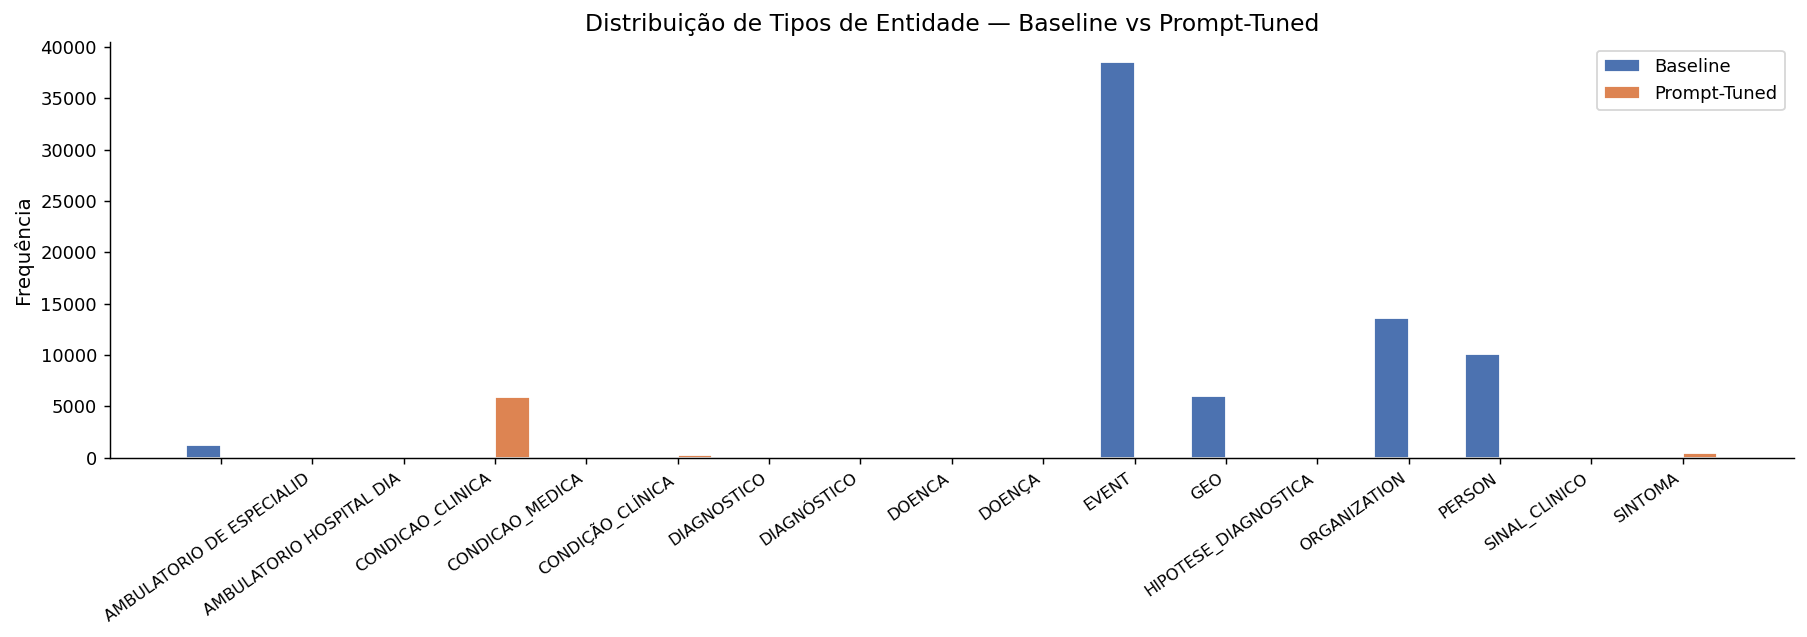

In [23]:
tipos_base  = df_base['tipo_entidade'].value_counts()
tipos_tuned = df_tuned['tipo_entidade'].value_counts()

# Alinha índices
todos_tipos = sorted(set(tipos_base.index) | set(tipos_tuned.index))
vals_base   = [tipos_base.get(t, 0) for t in todos_tipos]
vals_tuned  = [tipos_tuned.get(t, 0) for t in todos_tipos]

x = np.arange(len(todos_tipos))
w = 0.38

fig, ax = plt.subplots(figsize=(14, 5))
b1 = ax.bar(x - w/2, vals_base,  width=w, color=COR_BASE,  label='Baseline',      edgecolor='white')
b2 = ax.bar(x + w/2, vals_tuned, width=w, color=COR_TUNED, label='Prompt-Tuned', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels([t[:25] for t in todos_tipos], rotation=35, ha='right', fontsize=9)
ax.set_title('Distribuição de Tipos de Entidade — Baseline vs Prompt-Tuned', fontsize=13)
ax.set_ylabel('Frequência')
ax.legend()

plt.tight_layout()
plt.savefig('fig3_tipos_entidade.png', bbox_inches='tight')
plt.show()

## 6. Mudança de classificação por prontuário
Para cada prontuário presente nos dois datasets, verifica se a condição mais frequente mudou.

In [24]:
def doenca_principal(df):
    """Condição mais frequente por prontuário."""
    return (
        df.groupby('prontuario_id')['condicao']
        .agg(lambda x: x.value_counts().index[0])
        .reset_index()
        .rename(columns={'condicao': 'doenca_principal'})
    )

dp_base  = doenca_principal(df_base).rename(columns={'doenca_principal': 'doenca_base'})
dp_tuned = doenca_principal(df_tuned).rename(columns={'doenca_principal': 'doenca_tuned'})

comp = dp_base.merge(dp_tuned, on='prontuario_id', how='inner')
comp['mudou'] = comp['doenca_base'] != comp['doenca_tuned']

n_total  = len(comp)
n_mudou  = comp['mudou'].sum()
n_manteve = n_total - n_mudou

print(f'Prontuários em ambos os datasets : {n_total}')
print(f'  Mantiveram a mesma classificação : {n_manteve} ({n_manteve/n_total*100:.1f}%)')
print(f'  Mudaram a classificação          : {n_mudou}  ({n_mudou/n_total*100:.1f}%)')

# Mostra os que mudaram
if n_mudou > 0:
    print(f'\nExemplos de mudanças:')
    display(comp[comp['mudou']].head(10))

Prontuários em ambos os datasets : 262
  Mantiveram a mesma classificação : 0 (0.0%)
  Mudaram a classificação          : 262  (100.0%)

Exemplos de mudanças:


,prontuario_id,doenca_base,doenca_tuned,mudou
0,10001436,HEPATOLOGIA,ALTERAÇÕES DEGENERATIVAS ÓSSEAS,True
1,10002061,BOCA DA MATA,ASCITE,True
2,10005627,BRANQUINHA,ARBOVIROSE,True
3,10006674,PATIENT 10006674,ANEMIA,True
4,10013043,ABDOMINAL AND PELVIC CT SCAN,ABORTOS,True
5,10023174,ALAGOAS,ASCITE,True
6,10025831,PATIENT 10025831,COLELITÍASE,True
7,10036986,BRASILIA-DF,LITIASE RENAL,True
8,10041606,HEMORRHAGIC STROKE,HEPATOPATIA CRÔNICA,True
9,10041689,ABDOMINAL ULTRASOUND,DHGNA,True


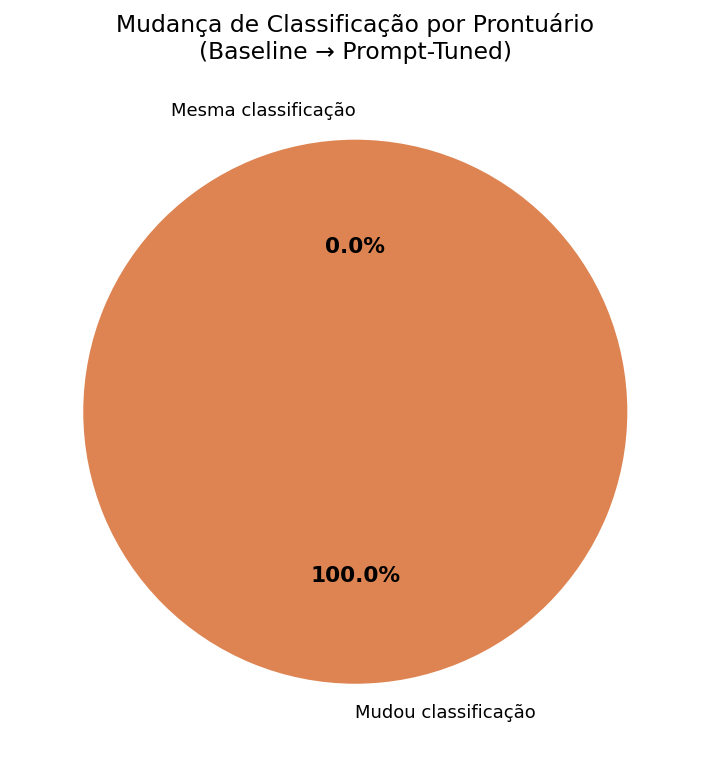

In [25]:
fig, ax = plt.subplots(figsize=(6, 6))

wedges, texts, autotexts = ax.pie(
    [n_manteve, n_mudou],
    labels=['Mesma classificação', 'Mudou classificação'],
    colors=[COR_DELTA, COR_TUNED],
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')

ax.set_title('Mudança de Classificação por Prontuário\n(Baseline → Prompt-Tuned)', fontsize=13)
plt.tight_layout()
plt.savefig('fig4_mudanca_classificacao.png', bbox_inches='tight')
plt.show()

## 7. Precision@K e Recall@K

**Definição aplicada ao contexto:**
- O **conjunto relevante** de cada prontuário é o conjunto de condições que **ambos os sistemas** extraíram (interseção = proxy de ground truth)
- **Precision@K**: dos K primeiros resultados retornados pelo sistema, quantos estão no conjunto relevante?
- **Recall@K**: dos itens relevantes, quantos foram capturados nos K primeiros resultados?

> Nota: sem ground truth anotado, a interseção dos dois sistemas serve como proxy conservador.

In [ ]:
def get_ranked_list(df, prontuario_id):
    """Retorna condições rankeadas por frequência para um prontuário."""
    sub = df[df['prontuario_id'] == prontuario_id]
    return list(sub['condicao'].value_counts().index)

def precision_at_k(ranked, relevant, k):
    top_k = ranked[:k]
    if not top_k:
        return 0.0
    return len(set(top_k) & set(relevant)) / k

def recall_at_k(ranked, relevant, k):
    top_k = ranked[:k]
    if not relevant:
        return 0.0
    return len(set(top_k) & set(relevant)) / len(relevant)

# Prontuários em comum
pront_comuns = sorted(
    set(df_base['prontuario_id'].unique()) & set(df_tuned['prontuario_id'].unique())
)

K_VALUES = [1, 3, 5, 10]
resultados = {k: {'P_base': [], 'R_base': [], 'P_tuned': [], 'R_tuned': []} for k in K_VALUES}

for pront in pront_comuns:
    ranked_base  = get_ranked_list(df_base,  pront)
    ranked_tuned = get_ranked_list(df_tuned, pront)

    # Relevante = interseção dos dois sistemas
    relevant = list(set(ranked_base) & set(ranked_tuned))
    if not relevant:
        continue

    for k in K_VALUES:
        resultados[k]['P_base'].append(precision_at_k(ranked_base,  relevant, k))
        resultados[k]['R_base'].append(recall_at_k(ranked_base,    relevant, k))
        resultados[k]['P_tuned'].append(precision_at_k(ranked_tuned, relevant, k))
        resultados[k]['R_tuned'].append(recall_at_k(ranked_tuned,   relevant, k))

# Médias
metricas = []
for k in K_VALUES:
    metricas.append({
        'K': k,
        'P@K Baseline':     np.mean(resultados[k]['P_base']),
        'P@K Prompt-Tuned': np.mean(resultados[k]['P_tuned']),
        'R@K Baseline':     np.mean(resultados[k]['R_base']),
        'R@K Prompt-Tuned': np.mean(resultados[k]['R_tuned']),
    })

df_metricas = pd.DataFrame(metricas).set_index('K')
print('Precision@K e Recall@K — médias sobre prontuários em comum')
print(df_metricas.round(4).to_string())

Precision@K e Recall@K — médias sobre prontuários em comum
    P@K Baseline  P@K Prompt-Tuned  R@K Baseline  R@K Prompt-Tuned
K                                                                 
1         0.0000            0.0000        0.0000            0.0000
3         0.0175            0.1053        0.0526            0.2053
5         0.0211            0.0737        0.1053            0.2316
10        0.0263            0.1000        0.2632            0.7789


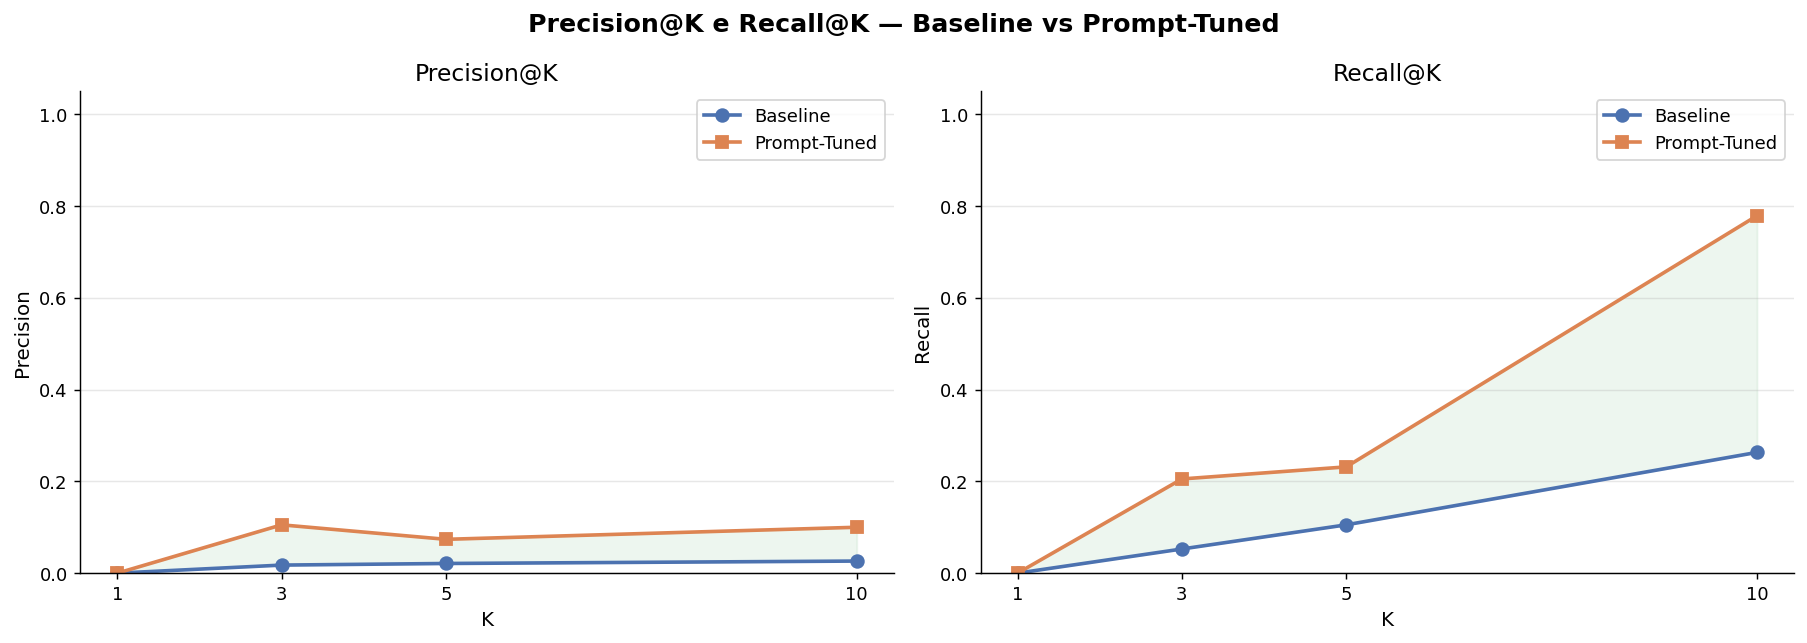

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Precision@K e Recall@K — Baseline vs Prompt-Tuned', fontsize=14, fontweight='bold')

ks = df_metricas.index.tolist()

# Precision@K
ax = axes[0]
ax.plot(ks, df_metricas['P@K Baseline'],     'o-', color=COR_BASE,  linewidth=2, markersize=7, label='Baseline')
ax.plot(ks, df_metricas['P@K Prompt-Tuned'], 's-', color=COR_TUNED, linewidth=2, markersize=7, label='Prompt-Tuned')
ax.fill_between(ks, df_metricas['P@K Baseline'], df_metricas['P@K Prompt-Tuned'],
                alpha=0.1, color=COR_DELTA)
ax.set_title('Precision@K')
ax.set_xlabel('K')
ax.set_ylabel('Precision')
ax.set_xticks(ks)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Recall@K
ax = axes[1]
ax.plot(ks, df_metricas['R@K Baseline'],     'o-', color=COR_BASE,  linewidth=2, markersize=7, label='Baseline')
ax.plot(ks, df_metricas['R@K Prompt-Tuned'], 's-', color=COR_TUNED, linewidth=2, markersize=7, label='Prompt-Tuned')
ax.fill_between(ks, df_metricas['R@K Baseline'], df_metricas['R@K Prompt-Tuned'],
                alpha=0.1, color=COR_DELTA)
ax.set_title('Recall@K')
ax.set_xlabel('K')
ax.set_ylabel('Recall')
ax.set_xticks(ks)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('fig5_precision_recall_k.png', bbox_inches='tight')
plt.show()

## 8. Sobreposição e exclusividade de entidades

Entidades só no Baseline       : 26499
Entidades só no Prompt-Tuned   : 2105
Entidades em ambos             : 312
Jaccard similarity             : 0.0108


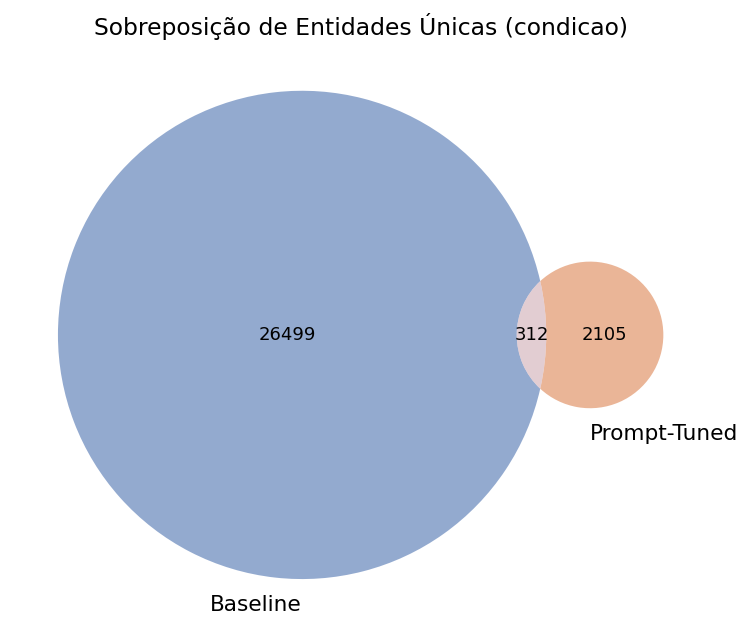

In [29]:
ents_base  = set(df_base['condicao'].unique())
ents_tuned = set(df_tuned['condicao'].unique())

so_base    = ents_base  - ents_tuned
so_tuned   = ents_tuned - ents_base
em_ambos   = ents_base  & ents_tuned

print(f'Entidades só no Baseline       : {len(so_base)}')
print(f'Entidades só no Prompt-Tuned   : {len(so_tuned)}')
print(f'Entidades em ambos             : {len(em_ambos)}')
print(f'Jaccard similarity             : {len(em_ambos) / len(ents_base | ents_tuned):.4f}')

fig, ax = plt.subplots(figsize=(8, 5))
from matplotlib_venn import venn2
try:
    venn2([ents_base, ents_tuned],
          set_labels=('Baseline', 'Prompt-Tuned'),
          set_colors=(COR_BASE, COR_TUNED),
          ax=ax, alpha=0.6)
    ax.set_title('Sobreposição de Entidades Únicas (condicao)', fontsize=13)
    plt.tight_layout()
    plt.savefig('fig6_venn.png', bbox_inches='tight')
    plt.show()
except ImportError:
    # Fallback sem matplotlib_venn
    vals  = [len(so_base), len(em_ambos), len(so_tuned)]
    rotulos = [f'Só Baseline\n({len(so_base)})', f'Ambos\n({len(em_ambos)})', f'Só Prompt-Tuned\n({len(so_tuned)})']
    cores_venn = [COR_BASE, COR_DELTA, COR_TUNED]
    bars = ax.bar(rotulos, vals, color=cores_venn, edgecolor='white', width=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                str(v), ha='center', fontweight='bold')
    ax.set_title('Sobreposição de Entidades Únicas', fontsize=13)
    ax.set_ylabel('Contagem')
    plt.tight_layout()
    plt.savefig('fig6_sobreposicao.png', bbox_inches='tight')
    plt.show()

## 9. Resumo executivo

In [30]:
p1_base  = df_metricas.loc[1, 'P@K Baseline']
p1_tuned = df_metricas.loc[1, 'P@K Prompt-Tuned']
r5_base  = df_metricas.loc[5, 'R@K Baseline']
r5_tuned = df_metricas.loc[5, 'R@K Prompt-Tuned']
jaccard  = len(em_ambos) / len(ents_base | ents_tuned)

print('=' * 55)
print('RESUMO EXECUTIVO')
print('=' * 55)
print(f'Prontuários avaliados        : {len(pront_comuns)}')
print(f'Entidades únicas — Baseline  : {len(ents_base)}')
print(f'Entidades únicas — Tuned     : {len(ents_tuned)}')
print(f'Jaccard (sobreposição)       : {jaccard:.4f}')
print(f'Prontuários que mudaram      : {n_mudou}/{n_total} ({n_mudou/n_total*100:.1f}%)')
print()
print(f'Precision@1 — Baseline       : {p1_base:.4f}')
print(f'Precision@1 — Prompt-Tuned   : {p1_tuned:.4f}  (delta: {p1_tuned-p1_base:+.4f})')
print()
print(f'Recall@5    — Baseline       : {r5_base:.4f}')
print(f'Recall@5    — Prompt-Tuned   : {r5_tuned:.4f}  (delta: {r5_tuned-r5_base:+.4f})')
print()
if p1_tuned > p1_base and r5_tuned >= r5_base:
    print('→ Prompt tuning melhorou tanto Precision quanto Recall.')
elif p1_tuned > p1_base:
    print('→ Prompt tuning melhorou Precision mas não Recall.')
elif r5_tuned > r5_base:
    print('→ Prompt tuning melhorou Recall mas não Precision.')
else:
    print('→ Diferença não conclusiva entre os sistemas.')
print('=' * 55)

RESUMO EXECUTIVO
Prontuários avaliados        : 262
Entidades únicas — Baseline  : 26811
Entidades únicas — Tuned     : 2417
Jaccard (sobreposição)       : 0.0108
Prontuários que mudaram      : 262/262 (100.0%)

Precision@1 — Baseline       : 0.0000
Precision@1 — Prompt-Tuned   : 0.0000  (delta: +0.0000)

Recall@5    — Baseline       : 0.1053
Recall@5    — Prompt-Tuned   : 0.2316  (delta: +0.1263)

→ Prompt tuning melhorou Recall mas não Precision.


In [5]:
import pandas as pd


# Quantas condições por prontuário em média?
por_pront = df_tuned.groupby("prontuario_id")["condicao"].nunique()
print("Condições por prontuário:")
print(por_pront.describe())
print()

# Quantas vezes cada condição aparece (quantos prontuários têm aquela condição)?
freq = df_tuned.groupby("condicao")["prontuario_id"].nunique().sort_values(ascending=False)
print("Top 20 condições mais frequentes:")
print(freq.head(20))
print()
print(f"Condições que aparecem em só 1 prontuário: {(freq == 1).sum()}")
print(f"Condições que aparecem em 5+ prontuários: {(freq >= 5).sum()}")

Condições por prontuário:
count    445.000000
mean      13.359551
std        9.053454
min        1.000000
25%        8.000000
50%       11.000000
75%       16.000000
max       61.000000
Name: condicao, dtype: float64

Top 20 condições mais frequentes:
condicao
ESQUISTOSSOMOSE                   115
ESPLENOMEGALIA                    114
HIPERTENSÃO PORTAL                105
ASCITE                             97
DISLIPIDEMIA                       97
HEPATOPATIA CRÔNICA                93
DIABETES MELLITUS                  86
VARIZES ESOFÁGICAS                 68
HEPATITE C                         58
FIBROSE PERIPORTAL                 56
HIPERTENSÃO ARTERIAL SISTÊMICA     53
VARIZES DE ESÔFAGO                 49
ANEMIA                             43
PLAQUETOPENIA                      42
DOR ABDOMINAL                      41
DOENÇA HEPÁTICA CRÔNICA            37
CIRROSE HEPÁTICA                   33
PRÉ-DIABETES                       32
COLELITÍASE                        30
GASTRITE         

In [6]:
doencas_alvo = [
    "ESQUISTOSSOMOSE", "HIPERTENSÃO PORTAL", "CIRROSE HEPÁTICA",
    "HEPATITE C", "HEPATITE B", "ESTEATOSE HEPÁTICA"
]

print("Cobertura das doenças prioritárias:")
for d in doencas_alvo:
    n = freq.get(d, 0)
    pct = n / 445 * 100
    print(f"  {d:<35} {n:>3} prontuários ({pct:.1f}%)")

Cobertura das doenças prioritárias:
  ESQUISTOSSOMOSE                     115 prontuários (25.8%)
  HIPERTENSÃO PORTAL                  105 prontuários (23.6%)
  CIRROSE HEPÁTICA                     33 prontuários (7.4%)
  HEPATITE C                           58 prontuários (13.0%)
  HEPATITE B                           11 prontuários (2.5%)
  ESTEATOSE HEPÁTICA                   16 prontuários (3.6%)


In [8]:
condicoes_unicas = sorted(df_tuned["condicao"].dropna().unique())

print(condicoes_unicas)

['ABAULAMENTO DISCAL', 'ABAULAMENTO DISCAL L4-L5 E L5-S1', 'ABAULAMENTO DISCAL L5-S1', 'ABCESSO HEPÁTICO', 'ABDOMEM EM AVENTAL', 'ABDOMEN FLÁCIDO', 'ABDOMEN GLOBOSO', 'ABORTO', 'ABORTOS', 'ABSCESSO DENTÁRIO', 'ABSCESSO EM MAMA', 'ABSCESSO HEPÁTICO', 'ABSCESSO PERIANAL COM FÍSTULA', 'ABSCESSOS INTRA-ABDOMINAIS', 'ABUSO SEXUAL', 'ACHADOS PULMONARES RESIDUAIS', 'ACIANÓTICA', 'ACIANÓTICO', 'ACIDENTE', 'ACIDENTE COM ARMA DE FOGO', 'ACIDENTE VASCULAR CEREBRAL', 'ACIDENTE VASCULAR CEREBRAL (AVC)', 'ACIDENTE VASCULAR CEREBRAL HEMORRÁGICO', 'ACIDENTE VASCULAR ENCEFALICO', 'ACIDENTE VASCULAR ENCEFÁLICO', 'ACIDENTE VASCULAR ENCEFÁLICO (AVE)', 'ACOLIA', 'ACOLIA FECAL', 'ADENOCARCINOMA DE CÓLON', 'ADENOCARCINOMA DE ENDOMÉTRIO', 'ADENOCARCINOMA DE RETO', 'ADENOCARCINOMA DE VESÍCULA BILIAR', 'ADENOCARCINOMA GÁSTRICO', 'ADENOMA ADRENAL', 'ADENOMA COM DISPLASIA LEVE', 'ADENOMA HEPATICO', 'ADENOMA HEPÁTICO', 'ADENOMA TUBULAR', 'ADENOMA TUBULAR COM DISPLASIA DE BAIXO GRAU', 'ADENOMA TUBULAR DE BAIXO GRAU

In [9]:
MAPA_NORMALIZACAO = {
    # Cirrose
    "CIRROSE": "CIRROSE HEPÁTICA",
    "CIRROSE HEPATICA": "CIRROSE HEPÁTICA",
    "CIRROSE HEPÁTICA DESCOMPENSADA": "CIRROSE HEPÁTICA",
    "CIRROSE HEPÁTICA ALCOÓLICA": "CIRROSE HEPÁTICA",
    "CIRROSE HEPÁTICA VIRAL C": "CIRROSE HEPÁTICA",
    "CIRROSE MICRONODULAR": "CIRROSE HEPÁTICA",
    "CIRROSE DESCOMPENSADA": "CIRROSE HEPÁTICA",
    "CIRROSE HEPÁTICA CRÔNICA": "CIRROSE HEPÁTICA",

    # Hipertensão portal
    "HIPERTENSAO PORTAL": "HIPERTENSÃO PORTAL",
    "HIPERTENSÃO PORTA": "HIPERTENSÃO PORTAL",
    "SINDROME DE HIPERTENSAO PORTAL": "HIPERTENSÃO PORTAL",
    "SÍNDROME DE HIPERTENSÃO PORTAL": "HIPERTENSÃO PORTAL",
    "SÍNDROME DA HIPERTENSÃO PORTAL": "HIPERTENSÃO PORTAL",
    "HIPERTENSÃO PORTAL NÃO CIRRÓTICA": "HIPERTENSÃO PORTAL",
    "HIPERTENSÃO PORTAL NÃO-CIRRÓTICA": "HIPERTENSÃO PORTAL",

    # Esquistossomose
    "EQUISTOSSOMOSE": "ESQUISTOSSOMOSE",
    "ESQUISTOSSOMOSE HEPATOESPLENICA": "ESQUISTOSSOMOSE",
    "ESQUISTOSSOMOSE HEPATOESPLÊNICA": "ESQUISTOSSOMOSE",
    "ESQUISTOSSOMOSE HEPATOESPLÊNICA (EHE)": "ESQUISTOSSOMOSE",
    "ESQUISTOSSOMOSE MANSONI": "ESQUISTOSSOMOSE",
    "ESQUISTOSSOMOSE MANSÔNICA": "ESQUISTOSSOMOSE",
    "EHE": "ESQUISTOSSOMOSE",
    "EHE/HP": "ESQUISTOSSOMOSE",

    # Hepatite C
    "HEPATITE C (HCV)": "HEPATITE C",
    "HEPATITE C CRÔNICA": "HEPATITE C",
    "HEPATITE CRÔNICA VIRAL": "HEPATITE C",  # checar contexto
    "HEPATITE CRÔNICA B": "HEPATITE B",

    # Hepatite B
    "HEPATITE B (HBV)": "HEPATITE B",
    "HEPATITE B CRONICA": "HEPATITE B",
    "HEPATITE B INATIVA": "HEPATITE B",
    "HEPATITE B RESOLVIDA": "HEPATITE B",
    "HEPATITE CRÔNICA VIRAL B": "HEPATITE B",
    "VÍRUS B (HEPATITE B)": "HEPATITE B",

    # Esteatose
    "ESTEATOSE": "ESTEATOSE HEPÁTICA",
    "ESTEATOSE HEPATICA": "ESTEATOSE HEPÁTICA",
    "ESTEATOSE HEPATICA DIFUSA": "ESTEATOSE HEPÁTICA",
    "DHGNA": "ESTEATOSE HEPÁTICA",
    "NAFLD": "ESTEATOSE HEPÁTICA",
    "MASLD": "ESTEATOSE HEPÁTICA",
    "MASH": "ESTEATOSE HEPÁTICA",
    "NASH": "ESTEATOSE HEPÁTICA",
    "DOENÇA HEPÁTICA GORDUROSA NÃO ALCOÓLICA": "ESTEATOSE HEPÁTICA",
    "DOENÇA HEPÁTICA GORDUROSA NÃO ALCOÓLICA (DHGNA)": "ESTEATOSE HEPÁTICA",
    "DOENÇA HEPÁTICA ESTEATÓTICA METABÓLICA": "ESTEATOSE HEPÁTICA",
    "DOENÇA HEPÁTICA ESTEATÓTICA METABÓLICA (MASH)": "ESTEATOSE HEPÁTICA",
    "ESTEATO-HEPATITE NÃO ALCOÓLICA": "ESTEATOSE HEPÁTICA",
    "ESTEATO-HEPATITE NÃO ALCOÓLICA (NASH)": "ESTEATOSE HEPÁTICA",
    "ESTEATOHEPATITE": "ESTEATOSE HEPÁTICA",
    "ESTEATOHEPATITE NÃO ALCOÓLICA": "ESTEATOSE HEPÁTICA",
    "DOENÇA HEPATICA ESTEATOSICA METABOLICA": "ESTEATOSE HEPÁTICA",
    "DOENÇA HEPATICA ESTEATOTICA METABOLICA": "ESTEATOSE HEPÁTICA",
}

In [4]:
df_tuned["prontuario_id"] = (
    df_tuned["prontuario_id"]
    .astype(str)
    .str.replace("PACIENTE - ", "", regex=False)
)

In [5]:
df_tuned.to_csv("prontuarios_tratados.csv", index=False)